In [8]:
%pip install mpmath

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


$\tilde{b}_1=0.0,\tilde{b}_2=0.0$　PVでのentanglement

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
from scipy.special import hankel1, hankel2, h1vp, h2vp
import mpmath as mp
import warnings

# WKB_Parity_Poster(2).ipynb と共通の文字サイズ
STYLE = {
    "figure_size": (9, 6),
    "font_family": "DejaVu Sans",
    "font_size": 14,
    "title_size": 20,
    "axis_label_size": 30,
    "tick_label_size": 14,
    "legend_size": 22,
}

plt.rcParams.update({
    "font.family": STYLE["font_family"],
    "font.size": STYLE["font_size"],
    "mathtext.fontset": "stix",
    "axes.unicode_minus": False,

    # 横軸・縦軸の名前
    "axes.labelsize": STYLE["axis_label_size"],

    # タイトル
    "axes.titlesize": STYLE["title_size"],

    # 横軸・縦軸の目盛りの数字
    "xtick.labelsize": STYLE["tick_label_size"],
    "ytick.labelsize": STYLE["tick_label_size"],

    # 凡例
    "legend.fontsize": STYLE["legend_size"],

    # 図の大きさ
    "figure.figsize": STYLE["figure_size"],
})

# ============================================================================
# 1. USER-EDITABLE PARAMETERS
# ============================================================================

# --- Background --------------------------------------------------------------
H = 1.0
MPL = 1.0

# The parity-violation scale appearing in c1 and c2.
# The equations depend on alpha/Lambda and beta/Lambda.
LAMBDA = 100000.0

# --- The two constant parity-violating parameters ----------------------------
# Example values chosen to satisfy |c1|,|c2|<1 over the default k range.
# The previous ALPHA=BETA=10 with LAMBDA=100, TAU0=-1, K_MAX=30 gives |c1|=3.
ALPHA = 1.0
BETA = 1.0

# cs_hyperu: Eq. (3.22) of Orlando-Akama-Lin, with canonical normalization
#            and complex conjugation for the Gaussian Riccati convention.
# gr_hankel: original instantaneous GR Hankel prescription for comparison.
INITIAL_MODE = "cs_hyperu"
CS_MPMATH_DPS = 30
CS_EXPANSION_WARN = 0.1  # warn when |alpha*k/(a*Lambda)| at TAU0 is above this

# --- Initial-state prescription ----------------------------------------------
# b0 and b2 are NOT entered by hand. They are determined for each k from
# the L/R auxiliary-mode initial conditions described in Sec. 3 of
# Graviton_entanglement.pdf.
#
# Conserved entanglement parameters
# btilde_i = A_i * exp(i * phi_i)

BTILDE1_AMP = 0.00
BTILDE1_PHASE = 0.0

BTILDE2_AMP = 0.00
BTILDE2_PHASE = 0.0

# The Riccati sign convention used in this code gives Re(B_sigma)>0 for the
# H^(2) auxiliary-mode branch. Set to 1 only if you intentionally want to
# reproduce the H^(1) choice written in Eqs. (3.8)-(3.9) of the notes.
HANKEL_BRANCH = 2
NU_TENSOR = 1.5

# --- Wavenumber grid ----------------------------------------------------------
K_MIN = 1.0
K_MAX = 30.0
N_K = 300

# --- Initial and final conformal times ---------------------------------------
# Exact de Sitter uses tau < 0.
TAU0 = -1.0

# Choose the common final time so that the largest k satisfies
#       -K_MAX * TAUF = SUPERHORIZON_X << 1.
SUPERHORIZON_X = 1.0e-3
TAUF = -SUPERHORIZON_X / K_MAX

# --- Numerical settings -------------------------------------------------------
RTOL = 1.0e-9
ATOL = 1.0e-11
METHOD = "DOP853"

# Number of saved time samples for checking the normalization margin.
# The zero-crossing event below provides the actual failure detector; these
# samples are used to record the minimum margin and for diagnostics.
N_TIME_CHECK = 600

# Strict theoretical conditions are margin > 0 and |c1| < 1.
# Small positive numerical safety margins avoid integrating exactly on a
# singular or non-normalizable boundary.
NORM_SAFETY = 1.0e-12
KINETIC_SAFETY = 1.0e-10

# Output
OUTPUT_DIR = Path("parity_violation_CS_BD_outputs") / "case_00"
CSV_NAME = "parity_violation_power_spectra.csv"


# ============================================================================
# 2. BACKGROUND AND PARITY COEFFICIENTS
# ============================================================================


def a_of_tau(tau):
    """Exact de Sitter scale factor a(tau) = -1/(H tau), tau < 0."""
    return -1.0 / (H * tau)


def beta_of_tau(tau):
    """beta(tau) = a(tau)^2 M_pl^2 / 2."""
    return a_of_tau(tau) ** 2 * MPL**2 / 2.0


def c1_of_tau_k(tau, k):
    """c1 = alpha k / (a Lambda)."""
    return ALPHA * k / (a_of_tau(tau) * LAMBDA)


def c2_of_tau_k(tau, k):
    """c2 = beta k / (a Lambda)."""
    return BETA * k / (a_of_tau(tau) * LAMBDA)


# ============================================================================
# 3. INITIAL GAUSSIAN KERNEL (CS hypergeometric or GR Hankel)
# ============================================================================


def c1_prime_of_tau_k(tau, k):
    """For constant ALPHA in exact de Sitter: c1' = c1/tau."""
    return c1_of_tau_k(tau, k) / tau
#-a'/a=1/\tauなので、c1' = alpha k / (a Lambda) * (-a'/a) = c1/tau

def z_sigma_sq(tau, k, helicity):
    """
    z_sigma^2 in Eq. (3.5).

    helicity = +1 : L,  beta_L^2 = beta (1+c1)
    helicity = -1 : R,  beta_R^2 = beta (1-c1)
    """
    c1 = c1_of_tau_k(tau, k)
    value = beta_of_tau(tau) * (1.0 + helicity * c1)
    if value <= 0.0:
        label = "L" if helicity == +1 else "R"
        raise ValueError(
            f"beta_{label}^2 must be positive at tau={tau:.8e}, k={k:.8e}; "
            f"got {value:.16e}"
        )
    return value

#これは、z_sigma'/z_sigmaを返す関数で、exact de Sitterとconstant ALPHAの条件下で計算される。z_sigma^2は beta * (1 + s * c1)であり、sは+1（L）または-1（R）である。beta'/betaは-1/tauであり、c1'はc1/tauである。
#2 * z_sigma' * z_sigma=2 * beta * (1+s c1) * beta'+ beta * beta *s c1'なので、z_sigma'/z_sigma=(beta'/beta +　s c1'/2(1+s c1))となる。
def z_sigma_log_derivative(tau, k, helicity):
    """
    Return z_sigma'/z_sigma for exact de Sitter and constant ALPHA.

    z_sigma^2 = beta (1+s c1),  s=+1(L), -1(R),
    beta'/beta = -1/tau, and c1' = c1/tau.
    """
    c1 = c1_of_tau_k(tau, k)
    c1_prime = c1_prime_of_tau_k(tau, k)
    denom = 1.0 + helicity * c1
    if denom <= 0.0:
        raise ValueError(
            f"1+s*c1 must be positive; got {denom:.16e} at k={k:.8e}"
        )

    beta_base_log_derivative = -1.0 / tau
    return (
        beta_base_log_derivative
        + helicity * c1_prime / (2.0 * denom)
    )


def effective_k_at_tau(tau, k, helicity):
    """
    k_tilde_sigma = k sqrt[(1+s c2)/(1+s c1)] from Eqs. (3.8)-(3.9).

    In the initial Hankel prescription below this is evaluated at TAU0 and
    then treated as the instantaneous/frozen frequency entering the initial
    data. For ALPHA=BETA (the CS line), k_tilde_L=k_tilde_R=k exactly.
    """
    c1 = c1_of_tau_k(tau, k)
    c2 = c2_of_tau_k(tau, k)
    den = 1.0 + helicity * c1
    num = 1.0 + helicity * c2
    if den <= 0.0 or num <= 0.0:
        label = "L" if helicity == +1 else "R"
        raise ValueError(
            f"Unstable/non-real {label} initial frequency at k={k:.8e}: "
            f"1+s*c1={den:.16e}, 1+s*c2={num:.16e}"
        )
    return k * np.sqrt(num / den)


def auxiliary_bd_mode_and_prime(tau, k_eff):
    """
    Return the auxiliary Hankel mode g and its conformal-time derivative.

        g(tau) = sqrt(-pi tau)/2 * H^(branch)_{3/2}(-k_eff tau).

    k_eff is treated as fixed when differentiating this initial-data ansatz.
    With the Riccati sign convention i B = z_sigma^2(g'/g-beta'/beta),
    branch H^(2) gives positive Re(B) in the GR/subhorizon limit.
    """
    if not tau < 0.0:
        raise ValueError("The de Sitter conformal time must satisfy tau < 0")
    if not k_eff > 0.0:
        raise ValueError("k_eff must be positive")

    x = -k_eff * tau
    pref = 0.5 * np.sqrt(-np.pi * tau)
    pref_prime = pref / (2.0 * tau)

    if HANKEL_BRANCH == 1:
        Hnu = hankel1(NU_TENSOR, x)
        Hnu_prime = h1vp(NU_TENSOR, x, 1)
    elif HANKEL_BRANCH == 2:
        Hnu = hankel2(NU_TENSOR, x)
        Hnu_prime = h2vp(NU_TENSOR, x, 1)
    else:
        raise ValueError("HANKEL_BRANCH must be 1 or 2")

    g = pref * Hnu
    g_prime = pref_prime * Hnu - k_eff * pref * Hnu_prime
    return g, g_prime


def cs_auxiliary_mode_and_prime(tau, k, helicity):
    """Analytic CS auxiliary g_sigma and derivative from Eq. (3.22).

    helicity: +1 -> L, -1 -> R (note's s_sigma).
    paper's lambda sign is alpha_lambda = -helicity.
    delta = H/M_CS = H*ALPHA/LAMBDA (signed).

    Positive-frequency *canonical* solution v_lambda is proportional to
      -i exp(-ik*tau) (2ik*tau)^2 U(2+i*alpha_lambda*delta/2,4,2ik*tau)
           /sqrt(2k) *exp(alpha_lambda*pi*delta/4).

    For i B=z^2(g'/g-z'/z), use g=conj(v_lambda), with W[g,g*]=-i.
    Its overall constant phase is irrelevant to B.
    """
    if tau >= 0.0 or k <= 0.0:
        raise ValueError("Require tau < 0 and k > 0")
    if not np.isclose(ALPHA, BETA, rtol=1.0e-12, atol=1.0e-14):
        raise ValueError("The CS solution (3.22) requires ALPHA == BETA")
    if abs(c1_of_tau_k(tau, k)) >= 1.0:
        raise ValueError("CS ghost boundary |c1| >= 1")

    paper_lambda = -helicity
    delta = H * ALPHA / LAMBDA

    # Continuously handle the GR limit, avoiding costly special functions.
    if delta == 0.0:
        e = np.exp(1j * k * tau)
        y = 1.0 + 1j / (k * tau)
        g = 1j * y * e / np.sqrt(2.0 * k)
        gp = 1j * e * (1j*k*y - 1j/(k*tau**2)) / np.sqrt(2.0*k)
        return complex(g), complex(gp)

    # Analytic derivative: dU(a,b,z)/dz = -a U(a+1,b+1,z).
    # Work with the conjugated argument to avoid ambiguous differentiation.
    with mp.workdps(CS_MPMATH_DPS):
        t = mp.mpf(tau)
        kk = mp.mpf(k)
        d = mp.mpf(delta)

        zc = -2j * kk * t
        ac = 2 - 0.5j * paper_lambda * d

        # Confluent hypergeometric functions
        U_num = mp.hyperu(ac, 4, zc)
        U_den = mp.hyperu(2, 4, zc)

        # Derivatives of U(a,b,z)
        U_num_shift = mp.hyperu(ac + 1, 5, zc)
        U_den_shift = mp.hyperu(3, 5, zc)

        phase = mp.exp(1j * kk * t)
        ampl = mp.exp(paper_lambda * mp.pi * d / 4)

        # Original expression from Eq. (3.22)
        pref = -1 / (t * mp.sqrt(2 * kk**3))

        g = (
            pref
            * (1 - 1j * kk * t)
            * phase
            * (U_num / U_den)
            * ampl
        )

        # Logarithmic derivative g'/g
        g_logprime = (
            -1 / t
            - 1j * kk / (1 - 1j * kk * t)
            + 1j * kk
            + 2j * kk * (
                ac * U_num_shift / U_num
                - 2 * U_den_shift / U_den
            )
        )

        gp = g * g_logprime

        return complex(g), complex(gp)



def initial_B_sigma(k, helicity):

    if INITIAL_MODE == "cs_hyperu":
        g, g_prime = cs_auxiliary_mode_and_prime(
            TAU0, k, helicity
        )

    elif INITIAL_MODE == "gr_hankel":
        k_eff = effective_k_at_tau(
            TAU0, k, helicity
        )
        g, g_prime = auxiliary_bd_mode_and_prime(
            TAU0, k_eff
        )

    else:
        raise ValueError("Unknown initial mode")

    # Fix the constant phase at the state-preparation time.
    rotation = np.exp(-1j * np.angle(g))

    g = rotation * g
    g_prime = rotation * g_prime

    z_sq = z_sigma_sq(TAU0, k, helicity)
    z_log_prime = z_sigma_log_derivative(
        TAU0, k, helicity
    )

    B_sigma = -1j * z_sq * (
        g_prime / g - z_log_prime
    )

    return B_sigma, g


def btilde1_of_k(k):
    del k
    return BTILDE1_AMP * np.exp(
        1j * BTILDE1_PHASE
    )


def btilde2_of_k(k):
    del k
    return BTILDE2_AMP * np.exp(
        1j * BTILDE2_PHASE
    )


def initial_b_of_k(k):
    """
    Initial Gaussian kernel [b0,b1,b2,b3]
    using the conserved parameters btilde1,btilde2.

    Based on Eqs. (3.55)-(3.58).
    """

    # 1. Diagonal vacuum kernels and auxiliary modes
    B_L, g_L = initial_B_sigma(k, helicity=+1)
    B_R, g_R = initial_B_sigma(k, helicity=-1)

    # 2. Trace and helicity-asymmetry components
    b0 = 0.5 * (B_L + B_R)
    b3 = 0.5 * (B_L - B_R)

    # 3. Helicity-dependent normalization functions
    z_L = np.sqrt(z_sigma_sq(TAU0, k, +1))
    z_R = np.sqrt(z_sigma_sq(TAU0, k, -1))

    # 4. Conserved entanglement parameters
    btilde1 = btilde1_of_k(k)
    btilde2 = btilde2_of_k(k)

    # 5. Eqs. (3.57)-(3.58)
    factor = z_L * z_R / (g_L * g_R)

    b1 = factor * btilde1
    b2 = factor * btilde2

    return np.array([b0, b1, b2, b3], dtype=complex)


# ============================================================================
# 4. PACK / UNPACK FOUR COMPLEX VARIABLES <-> EIGHT REAL VARIABLES
# ============================================================================

#bという4つの複素数の配列を実部と虚部に分けて8つの実数に変換する関数
def pack_b(b):
    """Pack [b0,b1,b2,b3] into 8 real numbers for solve_ivp."""
    b = np.asarray(b, dtype=complex)
    if b.shape != (4,):
        raise ValueError(f"pack_b expected shape (4,), got {b.shape}")

    return np.array(
        [
            b[0].real,
            b[0].imag,
            b[1].real,
            b[1].imag,
            b[2].real,
            b[2].imag,
            b[3].real,
            b[3].imag,
        ],
        dtype=float,
    )

#bという4つの複素数の配列を実部と虚部に分けて8つの実数に変換する関数の逆
def unpack_b(y):
    """Unpack 8 real numbers into complex [b0,b1,b2,b3]."""
    y = np.asarray(y, dtype=float)
    if y.shape != (8,):
        raise ValueError(f"unpack_b expected shape (8,), got {y.shape}")

    return np.array(
        [
            y[0] + 1j * y[1],
            y[2] + 1j * y[3],
            y[4] + 1j * y[5],
            y[6] + 1j * y[7],
        ],
        dtype=complex,
    )


def unpack_solution(y_matrix):
    """
    Convert solve_ivp sol.y with shape (8,N) into complex b with shape (4,N).
    """
    y_matrix = np.asarray(y_matrix, dtype=float)
    if y_matrix.ndim != 2 or y_matrix.shape[0] != 8:
        raise ValueError(
            f"unpack_solution expected shape (8,N), got {y_matrix.shape}"
        )

    return np.vstack(
        [
            y_matrix[0] + 1j * y_matrix[1],
            y_matrix[2] + 1j * y_matrix[3],
            y_matrix[4] + 1j * y_matrix[5],
            y_matrix[6] + 1j * y_matrix[7],
        ]
    )


# ============================================================================
# 5. EVOLUTION EQUATIONS: Eqs. (3.126)-(3.129)
# ============================================================================


def b_rhs_from_coefficients(b, k, beta, c1, c2):
    """
    Return complex derivatives [b0',b1',b2',b3'].

    This is a direct implementation of Eqs. (3.126)-(3.129).

    Each equation has the form
        i b_i' = F_i,
    therefore
        b_i' = -i F_i.
    """
    b0, b1, b2, b3 = np.asarray(b, dtype=complex)

    if beta <= 0.0:
        raise ValueError(f"beta must be positive, got {beta}")

    if abs(c1) >= 1.0 - KINETIC_SAFETY:
        raise ValueError(
            "Kinetic singularity/ghost boundary reached: "
            f"|c1|={abs(c1):.16e} must be < {1.0 - KINETIC_SAFETY:.16e}"
        )

    one_minus_c1_sq = 1.0 - c1**2

    # Eq. (3.126): i b0' = F0
    F0 = (
        ( b0**2 + b1**2 + b2**2 + b3**2 ) - (2.0 * c1 * b0 * b3)
    ) / (beta * one_minus_c1_sq) - beta * k**2

    # Eq. (3.127): i b2' = F2
    F3 = (
    2.0 * b0 * b3
    - c1 * (b0**2 - b1**2 - b2**2 + b3**2)
    ) / (beta * one_minus_c1_sq) - beta * c2 * k**2

    # Common coefficient in Eqs. (3.128) and (3.129)
    common = (
        2 * (b0 - c1*b3) / (beta * one_minus_c1_sq)
    )

    # Eq. (3.128): i b1' = F1
    F1 = common * b1

    # Eq. (3.129): i b3' = F3
    F2 = common * b2

    return -1j * np.array([F0, F1, F2, F3], dtype=complex)


def rhs_b_real(tau, y, k):
    """Eight-real-variable RHS passed to solve_ivp."""
    b = unpack_b(y)#ここでbはunpackによって4つの複素数の配列になっている
    beta = beta_of_tau(tau)
    c1 = c1_of_tau_k(tau, k)
    c2 = c2_of_tau_k(tau, k)
    db = b_rhs_from_coefficients(b, k, beta, c1, c2)#ここでbの微分を計算している
    return pack_b(db)#それをpackして8つの実数に変換して返す


# ============================================================================
# 6. NORMALIZABILITY AND KINETIC CONSISTENCY
# ============================================================================


def normalizability_margin_from_b(b):
    """
    Eq. (3.132) written as one inequality:

        Re(b0) > sqrt(Re(b1)^2 + Re(b2)^2 + Re(b3)^2).

    Positive return value means the state is normalizable.
    """
    b0, b1, b2, b3 = np.asarray(b, dtype=complex)
    radius = np.sqrt(b1.real**2 + b2.real**2 + b3.real**2)
    return b0.real - radius


def determinant_M_from_b(b):#4つの複素数の配列を受け取り、規格化条件を確認するための関数。
    """Eq. (3.131): det M using the real parts of b0,...,b3."""
    b0, b1, b2, b3 = np.asarray(b, dtype=complex)
    return b0.real**2 - b1.real**2 - b2.real**2 - b3.real**2


def kinetic_margin(tau, k):
    """Positive when |c1| < 1."""
    return 1.0 - abs(c1_of_tau_k(tau, k))


def normalizability_margin_from_y(y):#8つの実数の配列を受け取り、unpackして4つの複素数の配列に変換し、normalizability_margin_from_bを呼び出す。つまり8つの実数から規格化条件を確認するための関数。
    return normalizability_margin_from_b(unpack_b(y))


# ============================================================================
# 7. SOLVE ONE k MODE
# ============================================================================


def make_time_grid(tau0, tauf, n_samples):
    """
    Logarithmically sample |tau| while preserving increasing conformal time.
    Requires tau0 < tauf < 0.
    """
    abs_tau = np.geomspace(-tau0, -tauf, n_samples)
    return -abs_tau


def solve_one_mode(k):
    """
    Evolve one k mode from TAU0 to TAUF.

    The integration terminates if either
      (i) the normalizability margin reaches NORM_SAFETY, or
      (ii) the kinetic margin 1-|c1| reaches KINETIC_SAFETY.
    """
    b_init = initial_b_of_k(k)
    y0 = pack_b(b_init)

    norm0 = normalizability_margin_from_b(b_init)
    if norm0 <= NORM_SAFETY:
        raise ValueError(
            f"Initial state is not safely normalizable at k={k:.8e}: "
            f"margin={norm0:.16e}, required > {NORM_SAFETY:.16e}"
        )

    kin0 = kinetic_margin(TAU0, k)
    if kin0 <= KINETIC_SAFETY:
        raise ValueError(
            f"Initial kinetic condition fails at k={k:.8e}: "
            f"1-|c1|={kin0:.16e}, required > {KINETIC_SAFETY:.16e}"
        )

    t_eval = make_time_grid(TAU0, TAUF, N_TIME_CHECK)

    def fun(tau, y):
        return rhs_b_real(tau, y, k)

    def norm_event(tau, y):#時間発展の途中で規格化条件に接近しすぎたら止めるためのイベント関数
        del tau
        return normalizability_margin_from_y(y) - NORM_SAFETY

    norm_event.terminal = True#この event が発生したら ODE integration を停止する
    norm_event.direction = 0#event function が0をどちら向きに横切っても検出する+ ->-0, - -> +0でも停止する

    def kinetic_event(tau, y):
        del y
        return kinetic_margin(tau, k) - KINETIC_SAFETY

    kinetic_event.terminal = True#この event が発生したら ODE integration を停止する
    kinetic_event.direction = 0#event function が0をどちら向きに横切っても検出する+ ->-0, - -> +0でも停止する

    #ここでsolve_ivpを使ってbについてのODEを解く
    sol = solve_ivp(
        fun,
        (TAU0, TAUF),
        y0,
        method=METHOD,
        t_eval=t_eval,
        events=(norm_event, kinetic_event),
        rtol=RTOL,
        atol=ATOL,
    )

    if sol.t_events[0].size > 0:
        tau_fail = sol.t_events[0][0]
        raise RuntimeError(
            "Normalizability bound reached during evolution: "
            f"k={k:.8e}, tau={tau_fail:.16e}"
        )

    if sol.t_events[1].size > 0:
        tau_fail = sol.t_events[1][0]
        raise RuntimeError(
            "Kinetic boundary |c1|=1 reached during evolution: "
            f"k={k:.8e}, tau={tau_fail:.16e}"
        )

    if not sol.success:
        raise RuntimeError(
            f"ODE integration failed for k={k:.8e}: {sol.message}"
        )

    # Because TAUF is explicitly included in t_eval, a successful full
    # integration must end at TAUF up to floating-point tolerance.
    if not np.isclose(sol.t[-1], TAUF, rtol=0.0, atol=1.0e-13 * max(1.0, abs(TAUF))):
        raise RuntimeError(
            f"Integration for k={k:.8e} did not reach TAUF. "
            f"last tau={sol.t[-1]:.16e}, TAUF={TAUF:.16e}"
        )

    b_history = unpack_solution(sol.y)

    # Sampled diagnostic minimum. The event above is the actual zero-crossing
    # detector; this records how close the sampled trajectory came to the bound.
    b0r = b_history[0].real
    b1r = b_history[1].real
    b2r = b_history[2].real
    b3r = b_history[3].real
    norm_history = b0r - np.sqrt(b1r**2 + b2r**2 + b3r**2)
    min_norm_margin = np.min(norm_history)#ある時刻での各kに対応する規格化条件の中で一番やばい最小値を求める。

    c1_history = np.array([c1_of_tau_k(tau, k) for tau in sol.t])
    min_kinetic_margin = np.min(1.0 - np.abs(c1_history))

    if min_norm_margin <= 0.0:
        raise RuntimeError(
            f"Sampled normalizability violation at k={k:.8e}: "
            f"min margin={min_norm_margin:.16e}"
        )

    if min_kinetic_margin <= 0.0:
        raise RuntimeError(
            f"Sampled kinetic violation at k={k:.8e}: "
            f"min(1-|c1|)={min_kinetic_margin:.16e}"
        )

    return {
        "tau": sol.t,
        "b_history": b_history,
        "b_final": b_history[:, -1],
        "min_norm_margin": min_norm_margin,
        "min_kinetic_margin": min_kinetic_margin,
    }


# ============================================================================
# 8. CORRELATORS AND POWER SPECTRA: Eqs. (3.133)-(3.136)
# ============================================================================


def observables_from_b(k, b):
    """
    Compute final circular-basis correlations and primordial power spectra.

    D = det(M) = b0R^2 - b1R^2 - b2R^2 - b3R^2.

    Eq. (3.133): <h_L h_L*> = (b0R+b2R)/(2D)
    Eq. (3.134): <h_R h_L*> = (b3R-i b1R)/(2D)
    Eq. (3.135): <h_L h_R*> = (b3R+i b1R)/(2D)
    Eq. (3.136): <h_R h_R*> = (b0R-b2R)/(2D)
    """
    b0, b1, b2, b3 = np.asarray(b, dtype=complex)
    b0r, b1r, b2r, b3r = b0.real, b1.real, b2.real, b3.real

    norm_margin = normalizability_margin_from_b(b)
    if norm_margin <= 0.0:
        raise ValueError(
            f"Cannot compute observables for non-normalizable state at k={k:.8e}: "
            f"margin={norm_margin:.16e}"
        )

    D = determinant_M_from_b(b)
    if D <= 0.0:
        raise ValueError(
            f"det(M) must be positive at k={k:.8e}, got D={D:.16e}"
        )

    hh_LL = (b0r - b3r) / (2.0 * D)
    hh_RL = -(b1r + 1j * b2r) / (2.0 * D)
    hh_LR = -(b1r - 1j * b2r) / (2.0 * D)
    hh_RR = (b0r + b3r) / (2.0 * D)

    prefactor = k**3 / (2.0 * np.pi**2)

    P_LL = prefactor * hh_LL
    P_RL = prefactor * hh_RL
    P_LR = prefactor * hh_LR
    P_RR = prefactor * hh_RR

    P_total = P_LL + P_RR

    # Parity asymmetry convention requested here:
    # Pi = (P_LL-P_RR)/(P_LL+P_RR) = Re(b2)/Re(b0).
    Pi = (P_LL - P_RR) / P_total
    Pi_from_b = - b3r / b0r

    return {
        "D": D,
        "norm_margin": norm_margin,
        "hh_LL": hh_LL,
        "hh_RL": hh_RL,
        "hh_LR": hh_LR,
        "hh_RR": hh_RR,
        "P_LL": P_LL,
        "P_RL": P_RL,
        "P_LR": P_LR,
        "P_RR": P_RR,
        "P_total": P_total,
        "Pi": Pi,
        "Pi_from_b": Pi_from_b,
    }


# ============================================================================
# 10. CONFIGURATION VALIDATION
# ============================================================================


def validate_configuration():
    if H <= 0.0:
        raise ValueError("H must be positive")
    if MPL <= 0.0:
        raise ValueError("MPL must be positive")
    if LAMBDA <= 0.0:
        raise ValueError("LAMBDA must be positive")
    if K_MIN <= 0.0 or K_MAX <= 0.0 or K_MAX <= K_MIN:
        raise ValueError("Require 0 < K_MIN < K_MAX")
    if N_K < 2:
        raise ValueError("N_K must be at least 2")
    if N_TIME_CHECK < 2:
        raise ValueError("N_TIME_CHECK must be at least 2")
    if not (TAU0 < TAUF < 0.0):
        raise ValueError(
            f"Exact de Sitter setup requires TAU0 < TAUF < 0; got "
            f"TAU0={TAU0}, TAUF={TAUF}"
        )

    if BTILDE1_AMP < 0.0 or BTILDE2_AMP < 0.0:
        raise ValueError(
        "BTILDE1_AMP and BTILDE2_AMP "
        "must be non-negative")
    if HANKEL_BRANCH not in (1, 2):
        raise ValueError("HANKEL_BRANCH must be 1 or 2")
    if INITIAL_MODE not in ("cs_hyperu", "gr_hankel"):
        raise ValueError("INITIAL_MODE must be cs_hyperu or gr_hankel")
    if CS_MPMATH_DPS < 18:
        raise ValueError("Use CS_MPMATH_DPS >= 18")
    if INITIAL_MODE == "cs_hyperu":
        if not np.isclose(ALPHA, BETA, rtol=1e-12, atol=1e-14):
            raise ValueError("Eq. (3.22) is for CS gravity: require ALPHA=BETA")
        # Note |c1|=|alpha*k/(a*Lambda)|, not merely H/Lambda.
        max_expansion = abs(c1_of_tau_k(TAU0, K_MAX))
        if max_expansion >= CS_EXPANSION_WARN:
            warnings.warn(
                "CS Eq. (3.22) solves the linearized mode equation, while the "
                "Riccati evolution uses the unexpanded coefficients. "
                f"At TAU0, max |c1|={max_expansion:.5g}; "
                "reduce this toward << 1 for quantitative consistency.",
                RuntimeWarning, stacklevel=2,
            )
        # W = -i for normalized auxiliary modes. Check representative wavenumbers.
        for _k in (K_MIN, (K_MIN*K_MAX)**0.5, K_MAX):
            for _s in (+1, -1):
                g, gp = cs_auxiliary_mode_and_prime(TAU0, _k, _s)
                w = g * np.conjugate(gp) - gp * np.conjugate(g)
                if not np.allclose(w, -1j, rtol=1e-8, atol=1e-8):
                    raise RuntimeError(
                        f"Initial CS mode fails Wronskian test for k={_k}, s={_s}: {w}"
                    )

    # The new initial state is k-dependent, so validate it over the full scan.
    k_test = np.geomspace(K_MIN, K_MAX, max(20, min(N_K, 200)))
    min_norm0 = np.inf
    min_kin = np.inf
    min_grad = np.inf

    for k in k_test:
        c1 = c1_of_tau_k(TAU0, k)
        c2 = c2_of_tau_k(TAU0, k)
        min_kin = min(min_kin, 1.0 - abs(c1))
        min_grad = min(min_grad, 1.0 - abs(c2))

        # This also checks that the L/R effective frequencies are real.
        b_init = initial_b_of_k(k)
        margin = normalizability_margin_from_b(b_init)
        min_norm0 = min(min_norm0, margin)

    if min_kin <= KINETIC_SAFETY:
        raise ValueError(
            "The requested parameter range reaches |c1| >= 1 at TAU0. "
            f"Minimum 1-|c1| is {min_kin:.16e}."
        )
    if min_grad <= 0.0:
        raise ValueError(
            "The requested parameter range reaches |c2| >= 1 at TAU0, "
            "so one helicity has a non-positive gradient coefficient. "
            f"Minimum 1-|c2| is {min_grad:.16e}."
        )
    if min_norm0 <= NORM_SAFETY:
        raise ValueError(
            "The derived initial state plus the chosen b1/b3 does not satisfy "
            "the normalizability condition over the k range. "
            f"Minimum initial margin is {min_norm0:.16e}."
        )


# ============================================================================
# 11. OUTPUT HELPERS
# ============================================================================


def save_plots(results):
    x_initial = results["x_initial"]

    P_LL = results["P_LL"]
    P_RR = results["P_RR"]

    plt.figure(figsize=STYLE["figure_size"])

    plt.loglog(x_initial, P_LL, label=r"$P_{LL}$")
    plt.loglog(x_initial, P_RR, "--", label=r"$P_{RR}$")

    plt.xlabel(r"$x=-k\tau_i$", labelpad=11)
    plt.ylabel("Primordial power $\mathcal{P}$", labelpad=9)

    plt.legend()
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "parity_power_spectrum_LL_RR.png",
        dpi=220,
    )

    plt.show()
    plt.close()


def save_csv(results):
    b_final = results["b_final"]

    columns = np.column_stack(
        [
            results["k"],
            results["P_LL"],
            results["P_RR"],
            results["P_RL"].real,
            results["P_RL"].imag,
            results["P_LR"].real,
            results["P_LR"].imag,
            results["P_total"],
            results["Pi"],
            b_final[:, 0].real,
            b_final[:, 0].imag,
            b_final[:, 1].real,
            b_final[:, 1].imag,
            b_final[:, 2].real,
            b_final[:, 2].imag,
            b_final[:, 3].real,
            b_final[:, 3].imag,
            results["det_M_final"],
            results["norm_margin_final"],
            results["min_norm_margin"],
            results["min_kinetic_margin"],
            results["c1_initial"],
            results["c1_final"],
            results["c2_initial"],
            results["c2_final"],
        ]
    )

    header = ",".join(
        [
            "k",
            "P_LL",
            "P_RR",
            "Re_P_RL",
            "Im_P_RL",
            "Re_P_LR",
            "Im_P_LR",
            "P_total",
            "Pi_LL_minus_RR",
            "b0R_final",
            "b0I_final",
            "b1R_final",
            "b1I_final",
            "b2R_final",
            "b2I_final",
            "b3R_final",
            "b3I_final",
            "det_M_final",
            "norm_margin_final",
            "min_norm_margin_over_time",
            "min_kinetic_margin_over_time",
            "c1_initial",
            "c1_final",
            "c2_initial",
            "c2_final",
        ]
    )

    np.savetxt(
        OUTPUT_DIR / CSV_NAME,
        columns,
        delimiter=",",
        header=header,
        comments="",
    )


# ============================================================================
# 12. MAIN k SCAN
# ============================================================================


def main():
    validate_configuration()

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    k_array = np.geomspace(K_MIN, K_MAX, N_K)

    # 実際の計算開始時刻
    tau0 = -1.0 / K_MIN

    # 描画に使用する横軸
    x_initial = -tau0 * k_array

    P_LL = np.empty(N_K, dtype=float)
    P_RR = np.empty(N_K, dtype=float)
    P_RL = np.empty(N_K, dtype=complex)
    P_LR = np.empty(N_K, dtype=complex)
    P_total = np.empty(N_K, dtype=float)
    Pi = np.empty(N_K, dtype=float)

    b_final = np.empty((N_K, 4), dtype=complex)
    det_M_final = np.empty(N_K, dtype=float)
    norm_margin_final = np.empty(N_K, dtype=float)
    min_norm_margin = np.empty(N_K, dtype=float)
    min_kinetic_margin = np.empty(N_K, dtype=float)

    c1_initial = np.empty(N_K, dtype=float)
    c1_final = np.empty(N_K, dtype=float)
    c2_initial = np.empty(N_K, dtype=float)
    c2_final = np.empty(N_K, dtype=float)

    print("Running direct B-kernel parity-violation calculation")
    print(f"alpha = {ALPHA:.8e}")
    print(f"beta  = {BETA:.8e}")
    print(f"Lambda = {LAMBDA:.8e}")
    print(f"TAU0 = {TAU0:.8e}")
    print(f"initial mode method = {INITIAL_MODE}")
    if INITIAL_MODE == "cs_hyperu":
        print(f"H/M_CS = {H*ALPHA/LAMBDA:.8e}")
        print(f"max initial |c1| = {abs(c1_of_tau_k(TAU0, K_MAX)):.8e}")
    print(f"TAUF = {TAUF:.8e}")
    print(f"k range = [{K_MIN:.8e}, {K_MAX:.8e}] with N_K={N_K}")
    print()

    progress_step = max(1, N_K // 10)

    for i, k in enumerate(k_array):
        solution = solve_one_mode(k)
        bf = solution["b_final"]
        obs = observables_from_b(k, bf)

        b_final[i, :] = bf
        P_LL[i] = obs["P_LL"]
        P_RR[i] = obs["P_RR"]
        P_RL[i] = obs["P_RL"]
        P_LR[i] = obs["P_LR"]
        P_total[i] = obs["P_total"]
        Pi[i] = obs["Pi"]

        det_M_final[i] = obs["D"]
        norm_margin_final[i] = obs["norm_margin"]
        min_norm_margin[i] = solution["min_norm_margin"]
        min_kinetic_margin[i] = solution["min_kinetic_margin"]

        c1_initial[i] = c1_of_tau_k(TAU0, k)
        c1_final[i] = c1_of_tau_k(TAUF, k)
        c2_initial[i] = c2_of_tau_k(TAU0, k)
        c2_final[i] = c2_of_tau_k(TAUF, k)

        # Final identity checks for every k.
        if not np.allclose(P_LR[i], np.conjugate(P_RL[i]), rtol=1.0e-10, atol=1.0e-12):
            raise RuntimeError(f"Cross-spectrum Hermiticity check failed at k={k:.8e}")

        Pi_from_b = -bf[3].real / bf[0].real
        if not np.allclose(
            Pi[i], Pi_from_b, rtol=1.0e-9, atol=1.0e-11
        ):
            raise RuntimeError(f"Pi identity check failed at k={k:.8e}")

        if (i + 1) % progress_step == 0 or i == N_K - 1:
            print(f"  completed {i + 1:4d}/{N_K} modes")

    results = {
        "k": k_array,
        # 追加する2項目
        "tau_i": float(TAU0),
        "x_initial": -TAU0 * k_array,
        "P_LL": P_LL,
        "P_RR": P_RR,
        "P_RL": P_RL,
        "P_LR": P_LR,
        "P_total": P_total,
        "Pi": Pi,
        "b_final": b_final,
        "det_M_final": det_M_final,
        "norm_margin_final": norm_margin_final,
        "min_norm_margin": min_norm_margin,
        "min_kinetic_margin": min_kinetic_margin,
        "c1_initial": c1_initial,
        "c1_final": c1_final,
        "c2_initial": c2_initial,
        "c2_final": c2_final,
    }

    save_csv(results)
    save_plots(results)

    # Final global checks and concise diagnostics.
    global_min_norm = np.min(min_norm_margin)
    global_min_kin = np.min(min_kinetic_margin)
    max_cross_hermiticity_error = np.max(np.abs(P_LR - np.conjugate(P_RL)))
    max_Pi_identity_error = np.max(
        np.abs(Pi + b_final[:, 3].real / b_final[:, 0].real)
    )

    if global_min_norm <= 0.0:
        raise RuntimeError("Final review failed: normalization was violated")
    if global_min_kin <= 0.0:
        raise RuntimeError("Final review failed: |c1| < 1 was violated")

    print()
    print("Finished successfully.")
    print(f"minimum normalization margin over sampled (tau,k) = {global_min_norm:.8e}")
    print(f"minimum kinetic margin 1-|c1| over sampled (tau,k) = {global_min_kin:.8e}")
    print(f"max |P_LR - conj(P_RL)| = {max_cross_hermiticity_error:.8e}")
    print(f"max Pi identity error = {max_Pi_identity_error:.8e}")
    print()
    print("Outputs:")
    print(f"  {OUTPUT_DIR / CSV_NAME}")
    print(f"  {OUTPUT_DIR / 'parity_power_spectrum_LL_RR.png'}")
    print(f"  {OUTPUT_DIR / 'parity_asymmetry_Pi.png'}")
    print(f"  {OUTPUT_DIR / 'parity_cross_power_RL.png'}")
    print(f"  {OUTPUT_DIR / 'parity_normalizability_margin.png'}")
    return results


if __name__ == "__main__":
    results_00 = main()


Running direct B-kernel parity-violation calculation
alpha = 1.00000000e+00
beta  = 1.00000000e+00
Lambda = 1.00000000e+05
TAU0 = -1.00000000e+00
initial mode method = cs_hyperu
H/M_CS = 1.00000000e-05
max initial |c1| = 3.00000000e-04
TAUF = -3.33333333e-05
k range = [1.00000000e+00, 3.00000000e+01] with N_K=300



RuntimeError: Pi identity check failed at k=1.00000000e+00

$\tilde{b}_1=0.3,\tilde{b}_2=0.3$　PVでのentanglement

Running direct B-kernel parity-violation calculation
alpha = 1.00000000e+00
beta  = 1.00000000e+00
Lambda = 1.00000000e+05
TAU0 = -1.00000000e+00
initial mode method = cs_hyperu
H/M_CS = 1.00000000e-05
max initial |c1| = 3.00000000e-04
TAUF = -3.33333333e-05
k range = [1.00000000e+00, 3.00000000e+01] with N_K=300

  completed   30/300 modes
  completed   60/300 modes
  completed   90/300 modes
  completed  120/300 modes
  completed  150/300 modes
  completed  180/300 modes
  completed  210/300 modes
  completed  240/300 modes
  completed  270/300 modes
  completed  300/300 modes


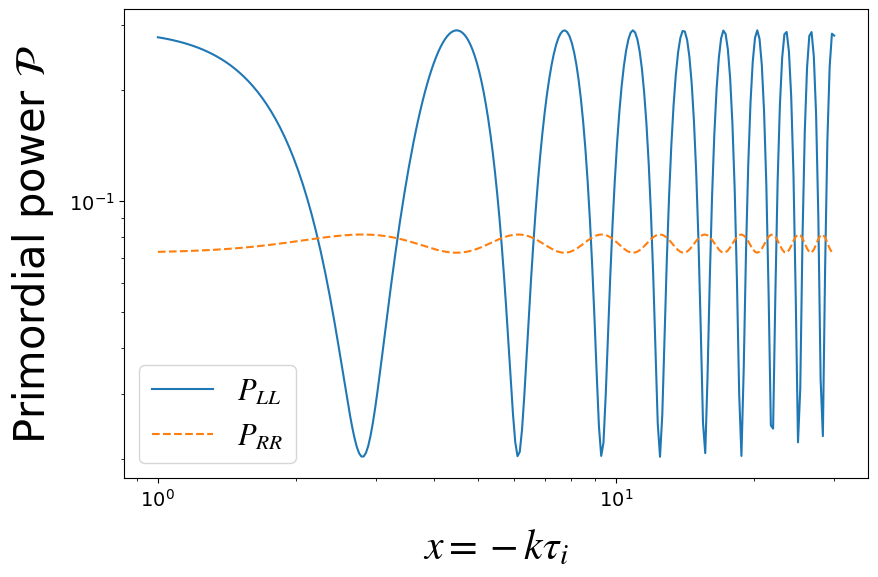


Finished successfully.
minimum normalization margin over sampled (tau,k) = 3.78679656e-02
minimum kinetic margin 1-|c1| over sampled (tau,k) = 9.99700000e-01
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 1.66533454e-16

Outputs:
  parity_violation_CS_BD_outputs/case_33/parity_violation_power_spectra.csv
  parity_violation_CS_BD_outputs/case_33/parity_power_spectrum_LL_RR.png
  parity_violation_CS_BD_outputs/case_33/parity_asymmetry_Pi.png
  parity_violation_CS_BD_outputs/case_33/parity_cross_power_RL.png
  parity_violation_CS_BD_outputs/case_33/parity_normalizability_margin.png


In [ ]:
BTILDE1_AMP = 0.30
BTILDE2_AMP = 0.30

OUTPUT_DIR = Path("parity_violation_CS_BD_outputs") / "case_33"

results_33 = main()

$\tilde{b}_1=0.1,\tilde{b}_2=0.3$　PVでのentanglement

Running direct B-kernel parity-violation calculation
alpha = 1.00000000e+00
beta  = 1.00000000e+00
Lambda = 1.00000000e+05
TAU0 = -1.00000000e+00
initial mode method = cs_hyperu
H/M_CS = 1.00000000e-05
max initial |c1| = 3.00000000e-04
TAUF = -3.33333333e-05
k range = [1.00000000e+00, 3.00000000e+01] with N_K=300

  completed   30/300 modes
  completed   60/300 modes
  completed   90/300 modes
  completed  120/300 modes
  completed  150/300 modes
  completed  180/300 modes
  completed  210/300 modes
  completed  240/300 modes
  completed  270/300 modes
  completed  300/300 modes


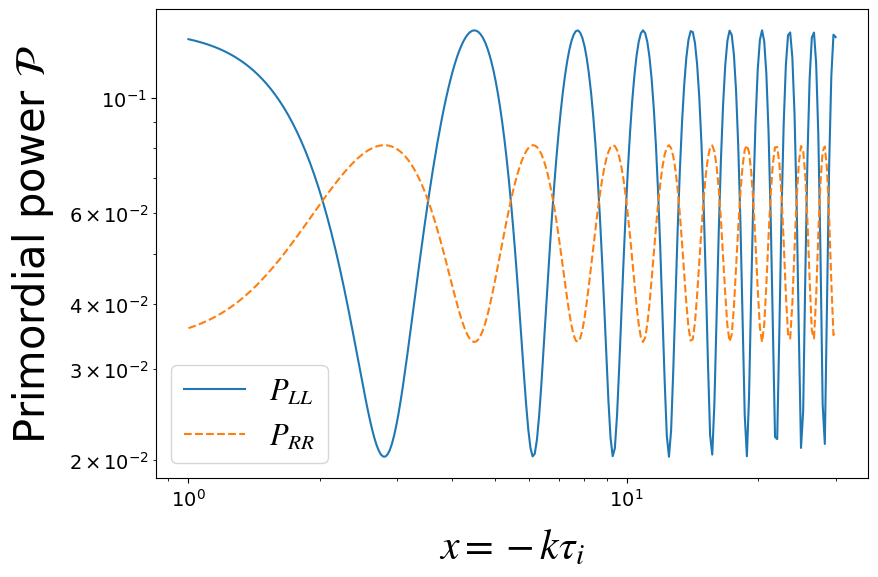


Finished successfully.
minimum normalization margin over sampled (tau,k) = 9.18861170e-02
minimum kinetic margin 1-|c1| over sampled (tau,k) = 9.99700000e-01
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 2.22044605e-16

Outputs:
  parity_violation_CS_BD_outputs/case_13/parity_violation_power_spectra.csv
  parity_violation_CS_BD_outputs/case_13/parity_power_spectrum_LL_RR.png
  parity_violation_CS_BD_outputs/case_13/parity_asymmetry_Pi.png
  parity_violation_CS_BD_outputs/case_13/parity_cross_power_RL.png
  parity_violation_CS_BD_outputs/case_13/parity_normalizability_margin.png


In [ ]:
BTILDE1_AMP = 0.30
BTILDE2_AMP = 0.10

OUTPUT_DIR = Path("parity_violation_CS_BD_outputs") / "case_31"

results_31 = main()

$\Pi$の比較グラフ

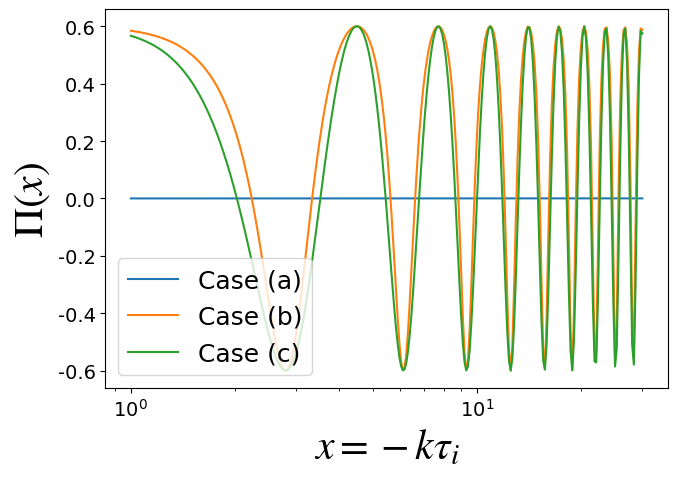

In [20]:
plt.figure(figsize=(7, 5))

plt.semilogx(
    results_00["x_initial"],
    results_00["Pi"],
    label=r"Case (a)"
)
plt.semilogx(
    results_33["x_initial"],
    results_33["Pi"],
    label=r"Case (b)"
)
plt.semilogx(
    results_13["x_initial"],
    results_13["Pi"],
    label=r"Case (c)"
)
plt.xlabel(r"$x=-k\tau_i$")
plt.ylabel(r"$\Pi(x)$")
plt.legend(fontsize=18)
plt.tight_layout()
comparison_dir = Path("parity_violation_CS_BD_outputs")
plt.savefig(comparison_dir / "Pi_comparison.png", dpi=220)
plt.show()